# 01 · Preprocessing — Maynard 2020 Lung Adenocarcinoma (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, characterise the manifold's transcriptional poles, and fix a single house
orientation for every downstream UMAP. Maynard is a **SmartSeq2** metastatic-LUAD atlas (EGFR/ALK-driven,
treated); malignant cells lack the published cell-cycle annotation (all NaN), so cell cycle is
scored **de novo** here where the confound test needs it.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Maynard2020_Lung | category: Lung


### Load malignant compartment

Maynard et al. supply a per-cell `cell_type` in which **Malignant** is an explicit label; the loader
exposes it as `celltype` and we take it directly (per protocol: use the publication's calls). Expression
is SmartSeq2 UMI counts → `normalize_total` + `log1p` (loader).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Maynard2020_Lung
Done.
full atlas: (19777, 26577)
malignant: (3184, 26577) | samples: 38
expression: X max 12.60 (log1p of normalize_total counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback

We look for the largest **multiplicative** cliff in the sorted per-sample counts (the natural
separatrix between tumour-bearing samples and spillover). Here the argmax gap (681→235, ratio 2.90)
sits *between two well-populated samples*, not at a spillover cliff: its top/runner-up ratio is only
1.16 (no dominant cliff) and the post-gap sample (235) is well above 2×floor. So the gap rule does
**not** fire and we fall back to the **≥100-cell floor** — the same floor the anchor used.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', n.values)
print('argmax gap %d->%d (ratio %.2f); top/second = %.2f; dominant cliff = %s'
      % (vals[gap], vals[gap+1], top, top/second, dominant))
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print('dominant spillover cliff -> geometric-mean threshold =', thresh)
else:
    thresh = FLOOR
    print('no dominant cliff (top gap ~ runner-up, separates well-populated samples) -> floor >=', FLOOR)
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept %d/%d samples (min per-sample = %d) -> %d cells'
      % (len(keep), len(n), int(n[n>=thresh].min()), adata.shape[0]))

sorted per-sample counts: [927 681 235 200 192 147 104  99  65  59  51  45  42  38  37  35  28  27
  27  25  18  14  14  13  13  11  10   9   5   2   2   2   2   1   1   1
   1   1]
argmax gap 681->235 (ratio 2.90); top/second = 1.16; dominant cliff = False
no dominant cliff (top gap ~ runner-up, separates well-populated samples) -> floor >= 100
kept 7/38 samples (min per-sample = 104) -> 2486 cells


### Overdispersion, PCA, Harmony integration, embedding

`theta` is derived from an integration-strength sweep (5→40) read on the **regenerated embedding**,
not a scalar alone. SmartSeq2 LUAD has a strong patient-specific batch effect (CNV/driver-driven), so
weak integration leaves a per-patient archipelago. iLISI rises 1.76→**1.95** from θ=5 to θ=20 and the
embedding collapses to one continuous mixed mass at θ=20 (single connected component); θ=40
**over-integrates** — it fragments into detached islands (main-component fraction 0.96) and distorts
the structure. **θ=20** is the derived optimum. `n_pcs=20` matches the Puram-40 / Kürten-20 scale.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
p = (adata.obs['sample'].value_counts()/adata.n_obs).values
floor_mix = float(np.sum(p**2))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [5, 10, 20, 40]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | perfect-mixing floor %.3f | pre-Harmony %.3f'
      % (floor_mix, base), '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 20
print('selected theta =', theta,
      '(iLISI peaks and the embedding becomes one continuous mixed mass at theta=20;',
      'theta=40 over-integrates into detached islands — see the sweep in the summary)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2800 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2800
2026-08-03 06:20:15,306 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 06:20:15,924 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 06:20:15,935 - harmonypy - INFO - Iteration 1 of 30
2026-08-03 06:20:16,491 - harmonypy - INFO - Iteration 2 of 30
2026-08-03 06:20:16,919 - harmonypy - INFO - Iteration 3 of 30
2026-08-03 06:20:17,347 - harmonypy - INFO - Iteration 4 of 30
2026-08-03 06:20:17,690 - harmonypy - INFO - Converged after 4 iterations
2026-08-03 06:20:17,768 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 06:20

### Remove detached islands (data-driven)

Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell outside
the main connected component — stripping physically detached specks while keeping the continuous termini.

In [6]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells,', adata.obs['sample'].nunique(), 'samples')

removed 90 cells in 2 detached islands
after island removal: 2396 cells, 7 samples


### Cell cycle (scored de novo) + developmental poles

The published `cell_cycle_phase`/`g1s`/`g2m` columns are **NaN for every malignant cell**, so cell
cycle is scored here from the standard Tirosh/Regev S + G2M gene lists — needed for the Gate-2 confound
test in 02. We then check for discrete sub-populations: low-resolution Leiden (res=0.15) does **not**
yield a balanced two-cluster split (it peels off only a small tail), confirming the malignant manifold
is a **single continuous developmental gradient** with no discrete subtypes — unlike the anchor's clean
Body/Cycling partition. Cycling is **diffuse** (~22%, not cluster-segregated). We therefore label the two
**poles** of the gradient deterministically from graph-smoothed module geography (robust to Harmony's
KMeans stochasticity): a somitogenesis-high **Body** (origin) opposite a neural-crest-like **Terminus**
(EMT-III / EpiSen-enriched per the publication's `mp_top` meta-programs) — grounding annotation in both
data-derived markers and the publication's reported malignant states.

In [7]:
# de-novo cell cycle (publication annotation is NaN for malignant cells)
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sn = [g for g in s_genes if g in adata.var_names]; gn = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=sn, g2m_genes=gn)
adata.obs['cycling'] = (adata.obs['phase'] != 'G1')
print('de-novo cell cycle | S %d / G2M %d genes | phase:' % (len(sn), len(gn)),
      adata.obs['phase'].value_counts().to_dict(), '| cycling frac %.3f' % adata.obs['cycling'].mean())

# score developmental modules to label poles by geography
feat_dir = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(feat_dir,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Ssm = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Ssm = A @ Ssm
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = Ssm[:,j]

# discrete-cluster probe: res=0.15 does not split the gradient into balanced clusters
sc.tl.leiden(adata, resolution=0.15, key_added='leiden015', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
lz = adata.obs['leiden015'].value_counts()
print('Leiden res=0.15 sizes:', lz.to_dict(),
      '-> no balanced discrete split (single continuous gradient)')

# deterministic pole labels from smoothed developmental-origin geography (Harmony-stochastic-robust)
origin_sm = adata.obs['pSom_sm'].values - adata.obs['Crest_sm'].values   # high = origin
adata.obs['compartment'] = pd.Categorical(
    np.where(origin_sm >= np.median(origin_sm), 'Body', 'Terminus'), categories=['Body','Terminus'])
print('poles (median origin-score split):', adata.obs['compartment'].value_counts().to_dict())
print('cycling fraction per pole:',
      adata.obs.groupby('compartment', observed=True)['cycling'].mean().round(3).to_dict())
print('samples per pole:',
      adata.obs.groupby('compartment', observed=True)['sample'].nunique().to_dict())

de-novo cell cycle | S 42 / G2M 54 genes | phase: {'G1': 1871, 'S': 277, 'G2M': 248} | cycling frac 0.219
Leiden res=0.15 sizes: {'0': 1559, '1': 837} -> no balanced discrete split (single continuous gradient)
poles (median origin-score split): {'Body': 1198, 'Terminus': 1198}
cycling fraction per pole: {'Body': 0.165, 'Terminus': 0.273}
samples per pole: {'Body': 7, 'Terminus': 7}


### House orientation — one consistent layout for every UMAP

The developmental axis is diagonal in the raw joint embedding, so all panels are shown after a single
**rigid rotation** to the house horizontal layout (distance-preserving — *not* a re-embedding). The
rotation angle is the manifold's axis of maximal variance; the sign is set so the somitogenesis-high /
neural-crest-low **origin** sits on the left. Stored as `X_umap_lin`.

In [8]:
S2 = adata.obs[['pSom_sm','Crest_sm']].values
origin_score = S2[:,0] - S2[:,1]     # pSom-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()                     # origin pole -> left (negative x)
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('manifold aspect (max/min std): %.2f' % aspect)
print('house orientation: rigid rotation %+.1fdeg (distances preserved), origin pole on left; X_umap_lin'
      % np.degrees(theta_rot))

manifold aspect (max/min std): 2.07
house orientation: rigid rotation +171.3deg (distances preserved), origin pole on left; X_umap_lin


### Gate 1 — batch mixing & manifold continuity

Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on the
regenerated embedding itself (see `samples.pdf` and the θ-sweep) plus a per-neighbourhood metric (iLISI).

In [9]:
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); pp = cnt/k; out[i] = 1.0/np.sum(pp**2)
    return out
n_samp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print('iLISI median: pre-Harmony %.2f -> post-Harmony(theta=20) %.2f of %d samples' % (il_pre, il_post, n_samp))
print('%d samples share one continuous manifold (one connected component after island removal);' % n_samp)
print('both poles (Body / Terminus) contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=20) 2.00 of 7 samples
7 samples share one continuous manifold (one connected component after island removal);
both poles (Body / Terminus) contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Save processed data

In [10]:
# coerce mixed-type object metadata to numeric where possible (else string) so the manifold serialises
protect = {'sample','patient','compartment','leiden015','celltype','cell_type','cell_subtype',
           'cell_cycle_phase','phase','source','disease','mp_top','mp_assignment'}
for col in adata.obs.columns:
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    cc = adata.obs[col]
    if cc.dtype == object:
        conv = pd.to_numeric(cc, errors='coerce')
        keep_num = cc.notna().sum() > 0 and conv.notna().sum() >= 0.9*cc.notna().sum()
        adata.obs[col] = conv if keep_num else cc.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2396, 21853)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 2396


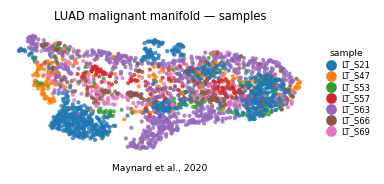

In [11]:
# House style (figsize=(3.5,1.5) horizontal strip, size=30) to match every other panel.
# Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence,
# on the house orientation (X_umap_lin) so this panel shares one orientation with 02/03/04.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('LUAD malignant manifold — samples', size=7.5)
ax.text(.5, -.12, '%s' % 'Maynard et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])
plt.show()